## 1. Imports and data loading

Place this notebook in the same folder as your main DNN notebook. It reads `../data/student-por.csv` (semicolon-separated).

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

SEED = 42
DATA_PATH = "../data/student-por.csv"
df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset shape:", df.shape)

Dataset shape: (649, 33)


## 2. Target creation and identical data splits

We classify `G3` into Low (0–9), Average (10–13), Good (14–20). We exclude `G1`, `G2`, and `G3` from model inputs to avoid grade-based shortcuts. Both splits use `random_state=42` and stratification, matching the main notebook.

In [26]:
def categorize_performance(g3):
    if g3 <= 9:
        return "Low"
    elif g3 <= 13:
        return "Average"
    return "Good"

df["performance_category"] = df["G3"].apply(categorize_performance)
X = df.drop(columns=["G1", "G2", "G3", "performance_category"])
y = df["performance_category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
print("Training:", X_train_final.shape, "Validation:", X_val.shape,
      "Test (held aside):", X_test.shape)

Training: (415, 30) Validation: (104, 30) Test (held aside): (130, 30)


## 3. Preprocessing without validation leakage

Fit `StandardScaler` and `OneHotEncoder` **only on training data**. Validation data is transformed with the same fitted transformer. Encode class labels and compute class weights using training labels only.

In [27]:
numerical_features = X_train_final.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train_final.select_dtypes(include=["object"]).columns.tolist()
preprocessor_final = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_final_processed = preprocessor_final.fit_transform(X_train_final)
X_val_processed = preprocessor_final.transform(X_val)

label_encoder_final = LabelEncoder()
y_train_final_encoded = label_encoder_final.fit_transform(y_train_final)
y_val_encoded = label_encoder_final.transform(y_val)
classes = np.unique(y_train_final_encoded)
weights = compute_class_weight(class_weight="balanced", classes=classes,
                               y=y_train_final_encoded)
class_weights_final = dict(zip(classes, weights))
print("Processed shapes:", X_train_final_processed.shape, X_val_processed.shape)
print("Classes:", list(label_encoder_final.classes_))
print("Class weights:", class_weights_final)

Processed shapes: (415, 56) (104, 56)
Classes: ['Average', 'Good', 'Low']
Class weights: {np.int64(0): np.float64(0.6093979441997063), np.int64(1): np.float64(1.1155913978494623), np.int64(2): np.float64(2.1614583333333335)}


## 4. Model Architecture and Evaluation Strategy

All experiments use the same DNN architecture:

- Input: 56 preprocessed features
- Hidden layers: 64 and 32 neurons with ReLU activation
- Dropout: Variable according to the experiment
- Output: 3 neurons with Softmax activation
- Optimizer: Adam
- Loss: Sparse Categorical Cross-Entropy
- Batch size: 32
- Maximum epochs: 100

### Early Stopping

Early Stopping monitors validation loss with a patience of 10 epochs and restores the weights from the epoch with the lowest validation loss.

The same training and validation datasets, preprocessing, class weights, and random seed are used across experiments.

### Evaluation Metrics

We compare:

- Peak validation accuracy during training
- Restored-model validation accuracy
- Macro F1-score
- Low-class recall
- Number of epochs trained

**Model selection:** Restored-model performance is more relevant than peak accuracy because Early Stopping restores weights based on validation loss, not accuracy.

These experiments are exploratory because the validation dataset is small.

In [28]:
def build_dnn(learning_rate=0.001, dropout_rate=0.3):
    model = Sequential([
        Input(shape=(X_train_final_processed.shape[1],)),
        Dense(64, activation="relu"),
        Dropout(dropout_rate),
        Dense(32, activation="relu"),
        Dropout(dropout_rate),
        Dense(3, activation="softmax"),
    ])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


from tensorflow.keras.callbacks import EarlyStopping

def run_experiment(learning_rate, dropout_rate, name):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_dnn(learning_rate, dropout_rate)

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_final_processed,
        y_train_final_encoded,
        validation_data=(X_val_processed, y_val_encoded),
        epochs=100,
        batch_size=32,
        class_weight=class_weights_final,
        callbacks=[early_stopping],
        verbose=0
    )

    predictions = np.argmax(
        model.predict(X_val_processed, verbose=0),
        axis=1
    )

    low_index = int(label_encoder_final.transform(["Low"])[0])

    return {
        "experiment": name,
        "learning_rate": learning_rate,
        "dropout": dropout_rate,

        "epochs_trained": len(history.history["loss"]),

        "best_val_accuracy": max(history.history["val_accuracy"]),

        "final_val_accuracy": accuracy_score(
            y_val_encoded, predictions
        ),

        "macro_f1": f1_score(
            y_val_encoded,
            predictions,
            average="macro",
            zero_division=0
        ),

        "low_recall": recall_score(
            y_val_encoded,
            predictions,
            labels=[low_index],
            average="macro",
            zero_division=0
        )
    }, history


## 5. Learning-rate experiments

Keep dropout fixed at **0.3**, then compare learning rates **0.0005, 0.001, 0.002**. **Important correction:** An older experiment cell used `0.005` while labeling it `0.0005`. This notebook runs the intended **0.0005** explicitly.

In [29]:
learning_rate_results = []
learning_rate_histories = {}
for lr in [0.0005, 0.001, 0.002]:
    print(f"Training learning rate {lr} ...")
    result, history = run_experiment(lr, 0.3, f"LR={lr}")
    learning_rate_results.append(result)
    learning_rate_histories[str(lr)] = history

lr_table = pd.DataFrame(learning_rate_results)
display(lr_table.style.format({
    "best_val_accuracy": "{:.2%}", "final_val_accuracy": "{:.2%}",
    "macro_f1": "{:.2%}", "low_recall": "{:.2%}"
}))

Training learning rate 0.0005 ...
Training learning rate 0.001 ...
Training learning rate 0.002 ...


,experiment,learning_rate,dropout,epochs_trained,best_val_accuracy,final_val_accuracy,macro_f1,low_recall
0,LR=0.0005,0.000500,0.300000,38,57.69%,55.77%,52.78%,43.75%
1,LR=0.001,0.001000,0.300000,24,61.54%,57.69%,54.37%,43.75%
2,LR=0.002,0.002000,0.300000,19,62.50%,58.65%,55.15%,43.75%


## 6. Dropout experiments

Keep learning rate fixed at **0.001**, then compare dropout rates **0.2, 0.3, 0.4**. The `0.3` configuration is the same model setting already evaluated in the learning-rate loop, so we reuse its result rather than training it twice.

In [30]:
dropout_results = []
dropout_histories = {}
for dropout in [0.2, 0.3, 0.4]:
    if dropout == 0.3:
        result = next(r for r in learning_rate_results if r["learning_rate"] == 0.001)
        history = learning_rate_histories["0.001"]
        result = dict(result, experiment="Dropout=0.3")
    else:
        print(f"Training dropout {dropout} ...")
        result, history = run_experiment(0.001, dropout, f"Dropout={dropout}")
    dropout_results.append(result)
    dropout_histories[str(dropout)] = history

dropout_table = pd.DataFrame(dropout_results)
display(dropout_table.style.format({
    "best_val_accuracy": "{:.2%}", "final_val_accuracy": "{:.2%}",
    "macro_f1": "{:.2%}", "low_recall": "{:.2%}"
}))

Training dropout 0.2 ...
Training dropout 0.4 ...


,experiment,learning_rate,dropout,epochs_trained,best_val_accuracy,final_val_accuracy,macro_f1,low_recall
0,Dropout=0.2,0.001000,0.200000,23,60.58%,58.65%,55.23%,43.75%
1,Dropout=0.3,0.001000,0.300000,24,61.54%,57.69%,54.37%,43.75%
2,Dropout=0.4,0.001000,0.400000,30,59.62%,56.73%,54.43%,50.00%


## 7. Compare learning curves

Validation accuracy can fluctuate on a small dataset. These curves show the trajectory rather than only one maximum value.

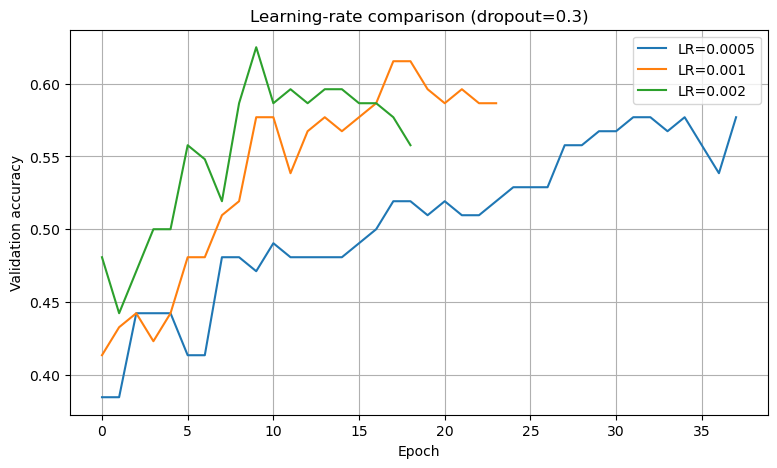

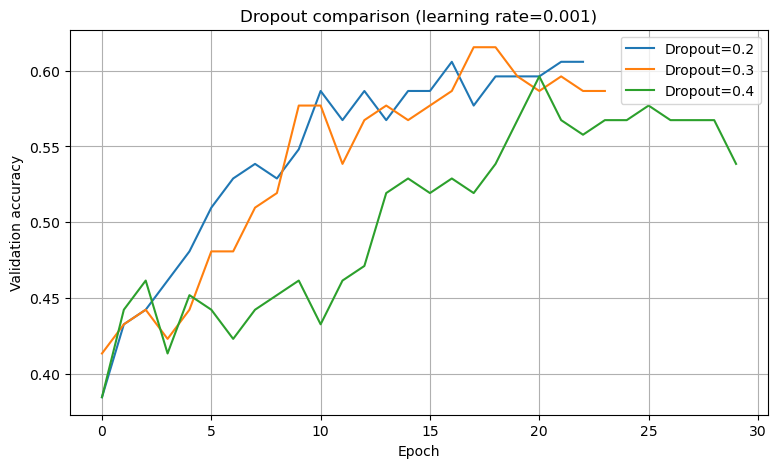

In [31]:
plt.figure(figsize=(9, 5))
for name, history in learning_rate_histories.items():
    plt.plot(history.history["val_accuracy"], label=f"LR={name}")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Learning-rate comparison (dropout=0.3)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
for name, history in dropout_histories.items():
    plt.plot(history.history["val_accuracy"], label=f"Dropout={name}")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Dropout comparison (learning rate=0.001)")
plt.legend()
plt.grid(True)
plt.show()

## 8. Combined Hyperparameter Experiment

The previous experiments varied learning rate and dropout separately.

Learning rate 0.002 achieved the highest restored validation accuracy in the learning-rate experiments, while dropout 0.2 achieved the highest restored validation accuracy in the dropout experiments.

We now test the combination:

- Learning rate: 0.002
- Dropout: 0.2

The objective is to determine whether combining these settings improves validation accuracy, macro F1-score, and Low-class recall.

In [33]:
combined_result, combined_history = run_experiment(
    learning_rate=0.002,
    dropout_rate=0.2,
    name="LR=0.002, Dropout=0.2"
)

comparison_results = [
    next(r for r in learning_rate_results if r["learning_rate"] == 0.001),
    next(r for r in learning_rate_results if r["learning_rate"] == 0.002),
    next(r for r in dropout_results if r["dropout"] == 0.2),
    combined_result
]

comparison_table = pd.DataFrame(comparison_results)

display(comparison_table.style.format({
    "best_val_accuracy": "{:.2%}",
    "final_val_accuracy": "{:.2%}",
    "macro_f1": "{:.2%}",
    "low_recall": "{:.2%}"
}))

,experiment,learning_rate,dropout,epochs_trained,best_val_accuracy,final_val_accuracy,macro_f1,low_recall
0,LR=0.001,0.001000,0.300000,24,61.54%,57.69%,54.37%,43.75%
1,LR=0.002,0.002000,0.300000,19,62.50%,58.65%,55.15%,43.75%
2,Dropout=0.2,0.001000,0.200000,23,60.58%,58.65%,55.23%,43.75%
3,"LR=0.002, Dropout=0.2",0.002000,0.200000,14,62.50%,50.96%,48.62%,43.75%


In [34]:
best_config = comparison_table.loc[
    comparison_table.sort_values(
        by=["final_val_accuracy", "macro_f1"],
        ascending=[False, False]
    ).index[0]
]

print("Selected configuration:")
print("Learning rate:", best_config["learning_rate"])
print("Dropout:", best_config["dropout"])
print(f"Restored accuracy: {best_config['final_val_accuracy']:.2%}")
print(f"Macro F1: {best_config['macro_f1']:.2%}")
print(f"Low recall: {best_config['low_recall']:.2%}")

Selected configuration:
Learning rate: 0.001
Dropout: 0.2
Restored accuracy: 58.65%
Macro F1: 55.23%
Low recall: 43.75%
